# K-Means++ Clustering on Social Network Ads

This Google Colab notebook follows the experiment shown in your photo. It uses **Age** and **EstimatedSalary** for clustering.

**Correction made:** inside the Elbow Method loop, `n_clusters` must be `i` (not always `1`). The notebook also includes data loading, scaling, the elbow graph, K-Means++ clustering, a cluster plot, and saving the results.

### Dataset
Expected CSV file: `Social_Network_Ads.csv`  
Expected columns: `Age` and `EstimatedSalary`.

You can load it from the Google Drive path shown in your practical book, or upload the CSV when prompted.

## 1. Import required libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df =pd.read_csv("/content/Social_Network_Ads.csv")

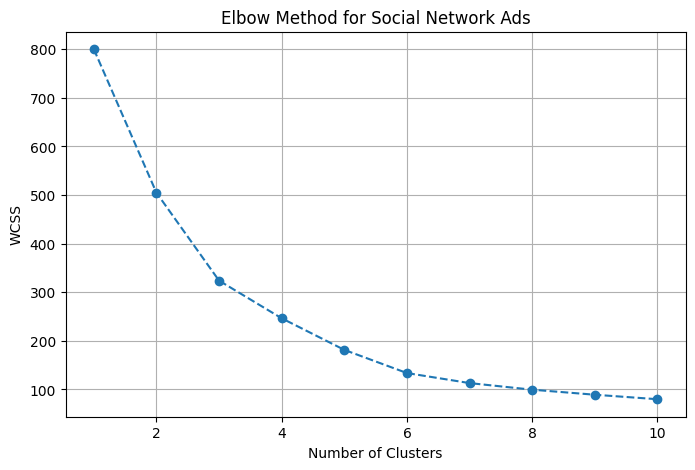

In [12]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Selecting the relevant features: Age and EstimatedSalary
X_ads = df[['Age', 'EstimatedSalary']].values

# Scale the features for better clustering performance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_ads)

# Find the optimal number of clusters using the Elbow Method
wcss_ads = []
for i in range(1, 11):
  kmeans_ads = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
  kmeans_ads.fit(X_scaled)
  wcss_ads.append(kmeans_ads.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_ads, marker='o', linestyle='--')
plt.title('Elbow Method for Social Network Ads')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

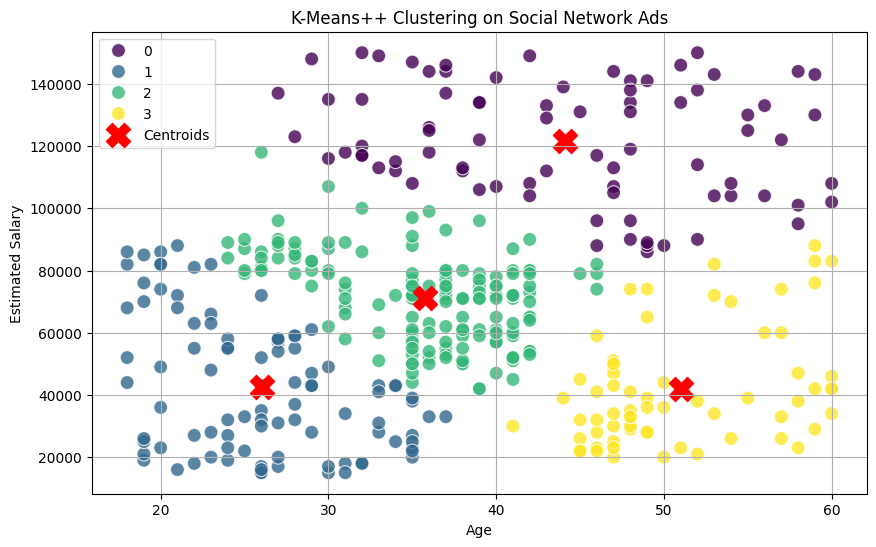

In [20]:
#Based on the elbow plot, let's assume 4 is the optimal number of clusters for
#this data distribution
optimal_clusters = 4
kmeans_ads = KMeans(n_clusters=optimal_clusters, init='k-means++', max_iter=300,
                    n_init=10, random_state=42)
y_kmeans_ads = kmeans_ads.fit_predict(X_scaled)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_ads[:, 0],
    y=X_ads[:, 1],
    hue=y_kmeans_ads,
    palette = 'viridis',
    s = 100,
    alpha=0.8
)
centroids = scaler.inverse_transform(kmeans_ads.cluster_centers_)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s = 300,
    c='red',
    label='Centroids',
    marker='X'
)
plt.title('K-Means++ Clustering on Social Network Ads')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.grid(True)
plt.show()

**​Viva Questions & Answers**

​1. What is the main difference between K-Means and K-Means++?

Standard K-Means picks all k initial centroids completely at random, which can lead to poor clustering or slow convergence if two centroids start too close together. K-Means++ picks the first centroid randomly and then selects subsequent centroids with a probability proportional to their squared distance from the closest existing centroid,
ensuring initial centers are well spread out.

​2. Why do we use StandardScaler in the code before clustering?

K-Means relies on Euclidean distance. In the Social_Network_Ads dataset, Age ranges roughly from 18 to 60, while EstimatedSalary ranges from 15,000 to 150,000. Without feature scaling (StandardScaler), EstimatedSalary would completely dominate the distance calculation.  

​3. What is WCSS and how does the Elbow Method work?

WCSS stands for Within-Cluster Sum of Squares (accessed via kmeans.inertia_ in scikit-learn). It measures the sum of squared distances between each data point and its assigned cluster centroid. As the number of clusters k increases, WCSS decreases. The "elbow" point on the graph—where the rate of decrease sharply slows down—indicates the optimal number of clusters.  

​4. What does n_init=10 mean in KMeans(...)?

It instructs the algorithm to run 10 times with different centroid seeds and return the best output (the one with the lowest WCSS/inertia).

Clean Lab Manual Write-Up (Experiment - 8)

​Aim: To implement K-Means++ Clustering.  
​

Objective:To implement clustering and compare its clustering quality and convergence with traditional random initialization.  
​

Theory:Standard K-Means relies on pure random initialization to select initial centroids. If initial centroids are placed close together, the algorithm can get trapped in suboptimal local minima. K-Means++ overcomes this drawback by using a smart centroid initialization technique that spreads out the initial centroids before running the standard K-Means iterations.  

​Algorithm:

​1. Choose the first centroid c_1 uniformly at random from the dataset points.

​2. For each data point x, compute its shortest distance D(x) to the nearest already chosen centroid.  

​3. Select a new centroid c_i from the remaining data points with a probability proportional to D(x)^2.  

​4. Repeat Steps 2 and 3 until k centroids are initialized.  

​5. Proceed with standard K-Means iterations:  
​Assignment: Assign each data point to its nearest centroid.  

​Update: Recompute each centroid's location as the mean of all points assigned to it.

​6. Convergence: Repeat the assignment and update steps until centroid positions stop changing.

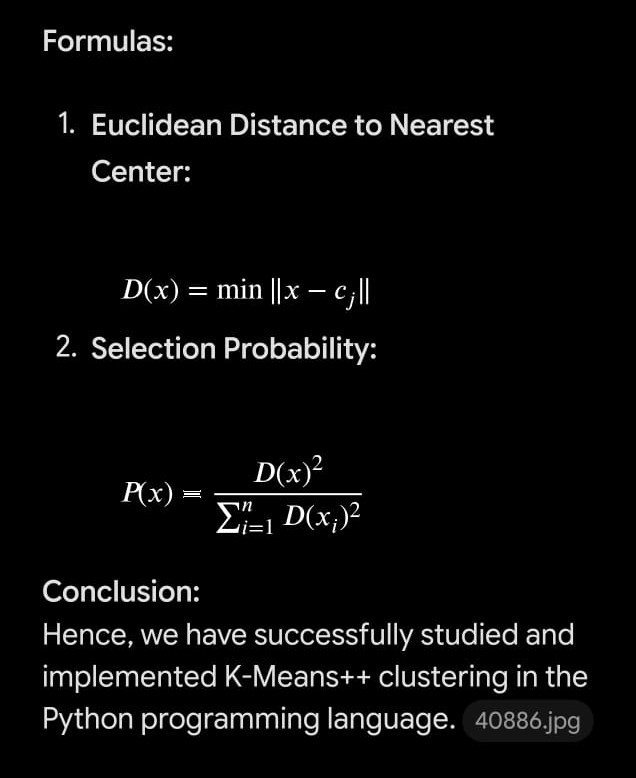